In [ ]:
# Uploading dataset to Colab
from google.colab import files
uploaded = files.upload()

Saving Churn_Modelling.csv to Churn_Modelling.csv


In [ ]:
import pandas as pd
data= pd.read_csv('Churn_Modelling.csv')

In [ ]:
data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:
data.isnull().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
data.dtypes

,0
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,int64
Geography,object
Gender,object
Age,int64
Tenure,int64
Balance,float64
NumOfProducts,int64


In [ ]:
# drop unnecessary columns
data = pd.read_csv('Churn_Modelling.csv')
data = data.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

# Convert categorical variables into 1s and 0s
data = pd.get_dummies(data, columns=['Geography', 'Gender'], drop_first=True, dtype=int)
data.head(5)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [ ]:
x= data.drop(columns=['Exited'])
y= data['Exited']

In [ ]:
x.sample(5)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
8600,710,43,9,128284.45,1,1,0,32996.89,0,0,1
7715,517,62,1,43772.66,3,1,0,187756.24,0,0,1
7077,649,24,7,101195.23,1,0,0,133091.32,1,0,1
8908,593,32,10,158537.42,1,1,0,166850.57,0,1,1
1366,645,37,7,0.00,2,1,0,13589.93,0,1,0


In [ ]:
# numerical columns to scale
cols_to_scale = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']

from sklearn.model_selection import train_test_split


x_train,x_test,y_train,y_test= train_test_split(x,y, test_size=0.2, random_state=42)

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

# Copies of the split datasets to retain original structure
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

# Fit on training data and transform both train and test sets
x_train_scaled[cols_to_scale] = scaler.fit_transform(x_train[cols_to_scale])
x_test_scaled[cols_to_scale] = scaler.transform(x_test[cols_to_scale])



In [ ]:
# Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

logistic= LogisticRegression()
logistic.fit(x_train_scaled, y_train)
y_pred_logistic= logistic.predict(x_test_scaled)

print('Logistic Model Accuracy: ', accuracy_score(y_test, y_pred_logistic)*100,'%')
# classification report for the Logistic Regression model
print(classification_report(y_test, y_pred_logistic))

Logistic Model Accuracy:  81.25 %
              precision    recall  f1-score   support

           0       0.83      0.96      0.89      1607
           1       0.57      0.19      0.29       393

    accuracy                           0.81      2000
   macro avg       0.70      0.58      0.59      2000
weighted avg       0.78      0.81      0.77      2000



Text(50.722222222222214, 0.5, 'Truth')

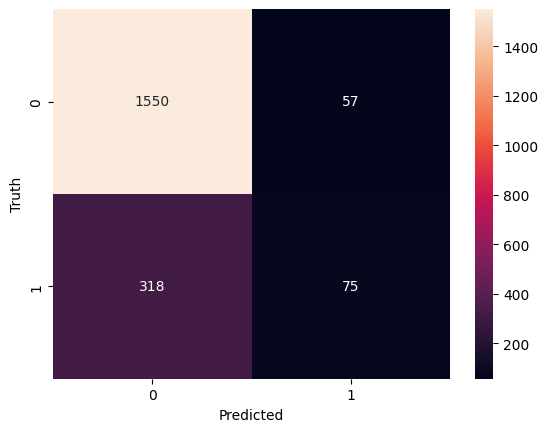

In [ ]:
# Confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm= confusion_matrix(y_test, y_pred_logistic)
sns.heatmap(cm, annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

Random Forest Model Accuracy:  86.7 %
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.76      0.47      0.58       393

    accuracy                           0.87      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000



Text(50.722222222222214, 0.5, 'Truth')

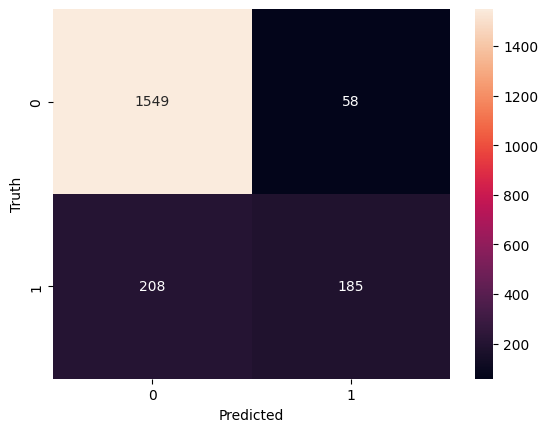

In [ ]:
# Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train_scaled, y_train)
y_pred_rf = rf_model.predict(x_test_scaled)

print('Random Forest Model Accuracy: ', accuracy_score(y_test, y_pred_rf) * 100, '%')
# classification report for the Random forest model
print(classification_report(y_test, y_pred_rf))

#Confusion matrix
cm= confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [06:42:55] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Model Accuracy:  86.55000000000001 %
              precision    recall  f1-score   support

           0       0.89      0.96      0.92      1607
           1       0.73      0.50      0.59       393

    accuracy                           0.87      2000
   macro avg       0.81      0.73      0.76      2000
weighted avg       0.86      0.87      0.86      2000



Text(50.722222222222214, 0.5, 'Truth')

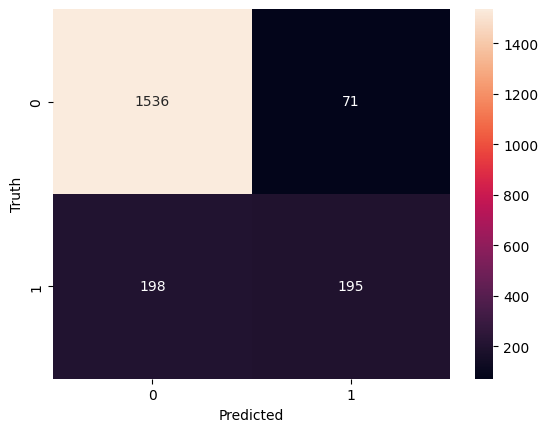

In [ ]:
# XGBoost Classifier
from xgboost import XGBClassifier

# Initialize and fit XGBoost
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, use_label_encoder=False, eval_metric='logloss')
xgb_model.fit(x_train_scaled, y_train)

# Predict and evaluate
y_pred_xgb = xgb_model.predict(x_test_scaled)

print('XGBoost Model Accuracy: ', accuracy_score(y_test, y_pred_xgb) * 100, '%')
# classification report for the XGBoost model
print(classification_report(y_test, y_pred_xgb))

#Confusion matrix
cm= confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(cm, annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')


In [ ]:
# Deep Learning model
import tensorflow as tf
from tensorflow import keras

# Get the actual number of features from the training data
num_features = x_train_scaled.shape[1]

model = keras.Sequential([
    keras.layers.Input(shape=(num_features,)),
    keras.layers.Dense(20, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(x_train_scaled, y_train, epochs=100)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7946 - loss: 0.4932
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7989 - loss: 0.4658
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8012 - loss: 0.4555
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8055 - loss: 0.4476
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8095 - loss: 0.4410
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8124 - loss: 0.4356
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8141 - loss: 0.4310
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8169 - loss: 0.4269
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8189 - loss: 0.4226
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8213 - loss: 0.4185
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8245 - loss: 0.4140
Epoch 12/100
250/250 ━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Evaluating the model
model.evaluate(x_test_scaled, y_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8635 - loss: 0.3360


[0.33604955673217773, 0.8634999990463257]

In [ ]:
y_predict_dl= model.predict(x_test_scaled)
y_predict_dl


63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


array([[0.03814583],
       [0.01455831],
       [0.12317064],
       ...,
       [0.67045283],
       [0.10621911],
       [0.24324697]], dtype=float32)

In [ ]:
y_pred_nn=[]
for val in y_predict_dl:
  if val> 0.5:
    y_pred_nn.append(1)
  else:
    y_pred_nn.append(0)

Neural networks  86.35000000000001 %
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1607
           1       0.77      0.44      0.56       393

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000



Text(50.722222222222214, 0.5, 'Truth')

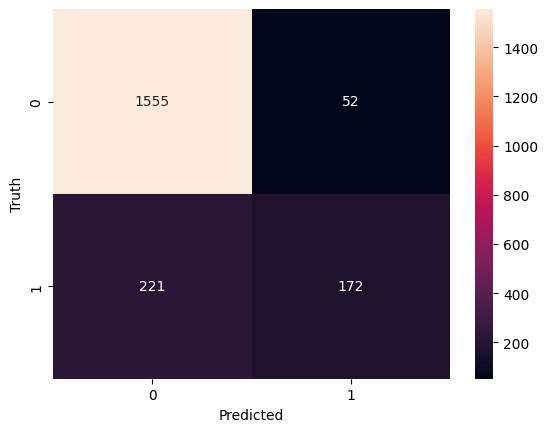

In [ ]:
print('Neural networks ', accuracy_score(y_test, y_pred_nn) * 100, '%')
# classification report for the Neural networks
print(classification_report(y_test, y_pred_nn))

# Confusion Matrix
cm= confusion_matrix(y_test, y_pred_nn)
sns.heatmap(cm, annot=True,fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')

Original training target distribution:
Exited
0    6356
1    1644
Name: count, dtype: int64

Resampled training target distribution (SMOTE):
Exited
0    6356
1    6356
Name: count, dtype: int64

Balanced XGBoost Model Accuracy:  85.6 %

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.92      0.91      1607
           1       0.65      0.59      0.62       393

    accuracy                           0.86      2000
   macro avg       0.77      0.76      0.76      2000
weighted avg       0.85      0.86      0.85      2000



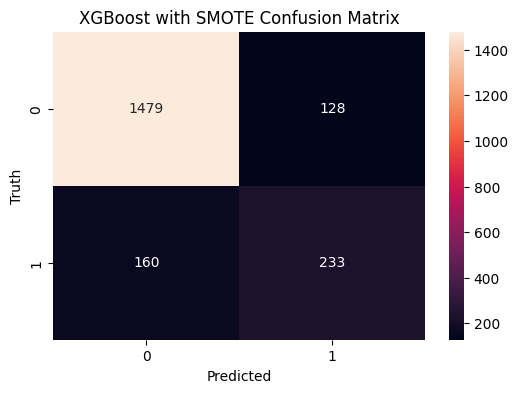

In [ ]:
# SMOTE to handle class imbalance
from imblearn.over_sampling import SMOTE
# Initialize and apply SMOTE to training data
smote = SMOTE(random_state=42)
x_train_resampled, y_train_resampled = smote.fit_resample(x_train_scaled, y_train)
print("Original training target distribution:")
print(y_train.value_counts())
print("\nResampled training target distribution (SMOTE):")
print(pd.Series(y_train_resampled).value_counts())

# XGBoost on SMOTE balanced data
xgb_model_balanced = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)
xgb_model_balanced.fit(x_train_resampled, y_train_resampled)

# Predict and evaluate on the untouched scaled test set
y_pred_xgb_balanced = xgb_model_balanced.predict(x_test_scaled)

print('\nBalanced XGBoost Model Accuracy: ', accuracy_score(y_test, y_pred_xgb_balanced) * 100, '%')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_xgb_balanced))

# 4. Display Confusion Matrix
plt.figure(figsize=(6, 4))
cm_balanced = confusion_matrix(y_test, y_pred_xgb_balanced)
sns.heatmap(cm_balanced, annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title('XGBoost with SMOTE Confusion Matrix')
plt.show()

 XGBoost with SMOTE performed better. The accuracy dropped from 86.5% to 85.6%. But this is not our deciding factor. As customer churn is a loss for the bank, focusing on the Recall is our priority. So XGBoost with SMOTE has a better Recall of 59% which is a jump from 50% in XGBoost with imbalanced class.


In [ ]:
# 1. Select 5 sample instances from the scaled test set
sample_features = x_test_scaled.sample(10)
sample_truth = y_test.sample(10)

# 2. Predict churn probabilities and class labels using the balanced XGBoost model
predictions = xgb_model_balanced.predict(sample_features)
probabilities = xgb_model_balanced.predict_proba(sample_features)[:, 1]

# 3. Present the results in a clean table
results_df = pd.DataFrame({
    'Actual Churn (Truth)': sample_truth.values,
    'Predicted Churn (Label)': predictions,
    'Probability of Churning': [f"{prob * 100:.2f}%" for prob in probabilities]
})

print("=== Testing Balanced XGBoost on 5 Test Samples ===")
display(results_df)

=== Testing Balanced XGBoost on 5 Test Samples ===


,Actual Churn (Truth),Predicted Churn (Label),Probability of Churning
0,0,0,12.43%
1,0,0,43.34%
2,1,0,2.17%
3,0,0,20.29%
4,0,0,8.16%
5,1,1,64.51%
6,0,1,69.00%
7,0,0,6.58%
8,1,0,7.50%
9,0,1,71.80%


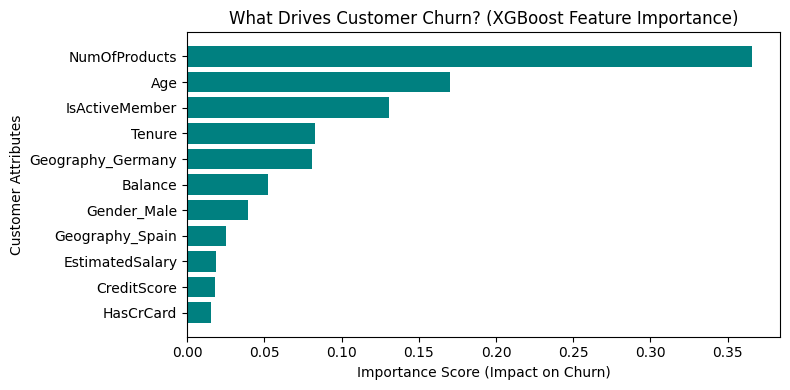

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances from our balanced XGBoost model
importances = xgb_model_balanced.feature_importances_
feature_names = x_train_scaled.columns

# Create a DataFrame for visualization
feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot the feature importances
plt.figure(figsize=(8, 4))
plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color='teal')
plt.xlabel('Importance Score (Impact on Churn)')
plt.ylabel('Customer Attributes')
plt.title('What Drives Customer Churn? (XGBoost Feature Importance)')
plt.tight_layout()
plt.show()

XGBoost Feature Importance chart, the top attributes represent the factors that the model found most valuable when splitting the data to decide whether a customer is likely to churn.

1. NumOfProducts (Importance Score: ~36.6%)

What it means: The number of products a customer holds with the bank has a massive influence on their loyalty.

Strategic Takeaway: Typically, there is a "sweet spot" (usually having exactly 2 products makes customers extremely loyal). If they only have 1 product, they have a high risk of leaving because they aren't deeply integrated into the bank's ecosystem. Conversely, if they have 3 or 4 products, they might be overwhelmed or experiencing service friction.

2. Age (Importance Score: ~17.0%)

What it means: A customer's life stage is highly predictive of churn. In retail banking, older customers often exhibit higher churn rates because they might be consolidating accounts, retiring, or looking for specific wealth management services that standard accounts don't offer.

Strategic Takeaway: Marketing and retention campaigns should be highly customized by demographic. Traditional accounts might work for younger users, but older demographics need specialized packages or high-yield options.

3. IsActiveMember (Importance Score: ~13.1%)
Whether the customer is actively interacting with the bank.

What it means: Inactive members,those who don't log in, use their cards, or make transactions, are significantly more likely to churn.

Strategic Takeaway: Re-engagement campaigns (like app notifications, cashback rewards, or personalized emails) should target these inactive members before they decide to leave officially.

4. Tenure (Importance Score: ~8.3%)

What it means: Newly acquired customers are generally more volatile than long-term customers.

Strategic Takeaway: Creating an Onboarding for customers who are new like tenures ranging 1-2 years.
